# <mark style="display:block; background:#d1c4e9; color:#1a1a1a; padding:6px 12px; border-radius:4px">9주차 · Streamlit 대시보드 — 추천 결과를 화면으로 보고 투자자별로 비교한다</mark>

## 한눈에 보기

| 질문 | 답 |
|---|---|
| **오늘 무엇을 하나요?** | 7주차 결과 파일(추천 3,000줄)을 읽어 **화면 세 개에 필요한 표와 비교**(투자자 한 명 · 투자 성향별 · 두 투자자 비교)를 직접 만들고, 같은 결과 파일을 읽는 **Streamlit 앱**을 강사 화면으로 봅니다 |
| **그 결과로 무엇이 생기나요?** | 노트북 안의 표와 비교, 그리고 웹 화면 앱 `dashboard_app.py` |
| **왜 하나요?** | 추천 담당자 · 상담 직원이 **코드를 보지 않고** 투자자별 추천을 확인하고 비교하게 하려는 것입니다 |
| **추천 내용이 바뀌나요?** | 아니요. 화면은 7주차 파일을 **읽어서 보여 줄 뿐**이고 학습하지 않습니다 |

---

## 왜 필요한가 — 예시 상황

8주차의 API 는 **프로그램**이 추천을 받는 길입니다. 그런데 상담 직원이나 운영 담당자는 JSON 을 읽지 못합니다. 추천이 제대로 나왔는지 **사람이 눈으로 확인**하려면 어떻게 해야 할까요?

| 문제 | 실제로 생기는 일 |
|---|---|
| CSV 파일을 열어서 찾아야 한다 | 3,000줄에서 상담할 투자자 번호로 **추천 10줄**을 찾아 읽어야 합니다 |
| 두 투자자를 비교하기 어렵다 | 「안정형과 공격형은 추천이 얼마나 다른가」를 설명하려면 줄을 하나씩 대조해야 합니다 |
| 위험도 상한이 지켜졌는지 한눈에 보이지 않는다 | 안정형 추천마다 위험도 4 · 5 가 있는지 확인해야 합니다 |
| 코드를 모르는 사람은 확인할 수 없다 | 노트북을 실행해야만 결과를 볼 수 있습니다 |

**오늘 해결하는 방법**
- 투자자를 고르면 그 사람의 추천이 **표**로 나오게 합니다
- 투자 성향별 위험도 분포를 **한 표**로 모아 상한이 지켜졌는지 봅니다
- 두 투자자의 추천에서 **같은 종목과 다른 종목**을 비교합니다
- 이 세 가지를 **웹 화면**(Streamlit)으로 만든 것을 봅니다

---

**8주차까지와 이어지는 곳 — 한눈에**

| 이어진 것 | 8주차까지 | 9주차 |
|---|---|---|
| 결과 파일 `recommendations.csv` | 7주차가 만들고, 8주차 API 가 켜질 때 읽습니다 | **화면이 같은 파일을 읽습니다** (API 를 부르지 않습니다) |
| 전달 방법 | API — 프로그램이 주소로 요청하고 JSON 으로 응답을 받습니다 | 화면 — **사람이 눈으로** 봅니다 |
| 위험도 상한 (6주차) | 8.3 에서 응답의 위험도가 3 이하인 것을 확인했습니다 | 9.3 에서 성향별 분포로 확인합니다 |
| 인증 · 권한 (8.8) | 번호만 알면 누구나 요청할 수 있었습니다 | 화면도 번호를 고를 수 있으면 누구나 확인합니다 (9.6) |
| 배포 (8.9) | 개념만 보았습니다 | 10주차에서 배포 조건을 점검합니다 (실제 배포는 하지 않습니다) |

---

## 오늘 만드는 것 — 미리 보기

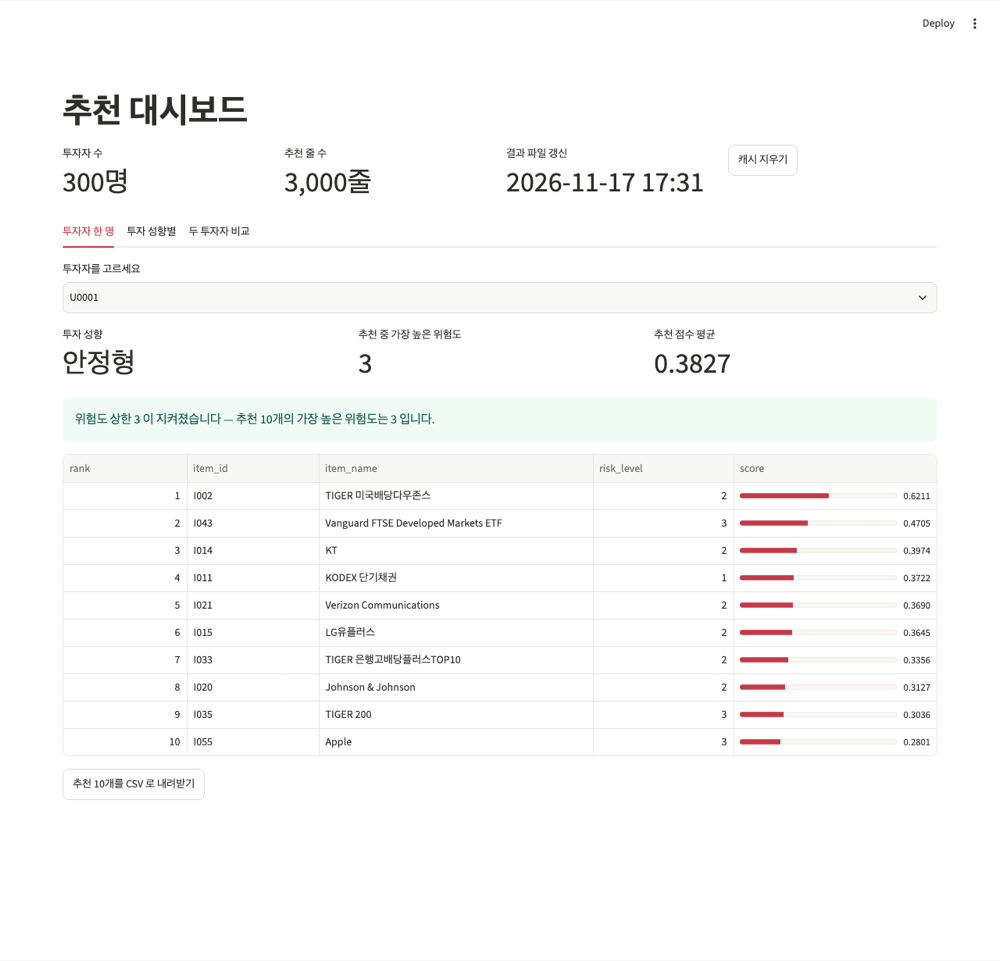

위 그림은 `dashboard_app.py` 를 실제로 켜서 찍은 화면(**투자자 한 명** 탭)입니다. 맨 위 「추천 대시보드」 아래에 탭 세 개가 있고, 투자자를 고르면 요약 정보 세 가지, 「위험도 상한이 지켜졌는지」 점검, 점수 막대가 있는 추천 10개 표가 나옵니다.

- 노트북에서는 **같은 내용을 pandas 로 직접 만들고**, 웹 화면은 강사가 켜서 보여 줍니다.
- 웹 화면 코드는 **`dashboard_app.py` 파일 하나**에 들어 있습니다.

---

### 오늘의 구성 — 50분

| 시간 | 어디서 | 하는 일 |
|---|---|---|
| 개념 30분 | 강사 설명 | 이 노트북의 「오늘 나오는 말」 표 — 대시보드 · Streamlit · 위젯 · 다시 실행 · 캐시 · 분포 · 비교와 해석 · 배포 · 개인정보 |
| 실습 20분 | **이 노트북** | 모두 실행 → 9.1 재료 확인 → 9.2 투자자 한 명 → 9.3 성향별 분포 → 9.4 두 투자자 비교 → 9.5 Streamlit 앱 (강사 시연 · 수강생은 코드 읽기) |

### 이 노트북 읽는 법 — 🎯 와 📖

- **🎯 수업** — 수업 시간에 셀을 실행하고 **결과를 함께 읽는** 절입니다 (9.1 \~ 9.5)
- **📖 선택 복습 · 혼자 읽기** — 9.0 은 curl 복습, 9.6 \~ 9.7 은 수업에서 건너뛰고 복습할 때 읽는 절입니다.

⏱ **실습을 시작하면 먼저 메뉴의 `런타임 → 모두 실행` 을 눌러 두세요.** 7주차 결과 파일 만들기까지 10초쯤 걸립니다.

> 💡 **Streamlit 앱은 이 Colab 에서 켜지 않습니다.** 강사가 자기 컴퓨터에서 켜서 화면으로 보여 줍니다. 이유는 9.5 에 있습니다. 대신 앱에 들어가는 내용은 모두 이 노트북에서 직접 실행합니다. 내 컴퓨터에서 앱을 직접 켜 보는 것은 **수업 후 선택**입니다 (9.6).

## <mark style="display:block; background:#c8e6c9; color:#1a1a1a; padding:6px 12px; border-radius:4px">시작하기 · 이 노트북을 여는 법</mark>

1. https://colab.research.google.com/github/welovecherry/recsys/blob/main/notebooks/09_dashboard.ipynb
2. 구글 계정으로 로그인합니다.
3. **경고창이 뜨면 `Run anyway` 를 누릅니다.**
4. **아래 셀의 ▶ 버튼을 누릅니다.** 실습 자료를 받아옵니다. 10초쯤 걸립니다.
5. 그다음부터는 위에서 아래로 셀을 하나씩 실행하면 됩니다.

> ⚠ **고친 내용을 남기려면** 메뉴에서 `파일 → 드라이브에 사본 저장` 을 눌러 주세요.

> ⚠ **오류가 나거나 지난번 실행 내용이 남아 있는 것 같으면** `런타임 → 세션 다시 시작` 을 누른 뒤 `런타임 → 모두 실행` 을 누르세요.

---

**이 노트북이 쓰는 것**

| 무엇 | 어디에 | 쓰임 |
|---|---|---|
| `recommend_batch.py` | `notebooks/` 폴더 | 7주차 스크립트 — 결과 파일 `output/recommendations.csv` 를 만든다 |
| `dashboard_app.py` | `notebooks/` 폴더 | **오늘의 산출물** — 결과 파일을 읽어 화면으로 보여 주는 Streamlit 앱 (9.5 에서 코드를 읽는다) |
| `recommend_api.py` | `notebooks/` 폴더 | 선택 복습 — 8주차 API 를 켜고 `curl` 로 응답 확인 (9.0) |
| `items.csv` · `users.csv` · `interactions.csv` | `data/` 폴더 | 7주차 스크립트가 읽는 데이터 |

- 모두 **파일**입니다. 아래 셀이 저장소를 `/content/recsys` 에 내려받으면 Colab 왼쪽의 📁 에서 볼 수 있습니다. 처음에는 `sample_data` 만 보이고, 셀을 실행한 뒤 ↻ 를 누르면 `recsys` 폴더가 생깁니다.

⚠ **지난주 노트북을 먼저 실행할 필요가 없습니다.** 7주차 결과 파일도 이 노트북이 다시 만듭니다.

⚠ **대시보드 실습에는 따로 설치할 것이 없습니다.** pandas 만 씁니다. 선택 복습 9.0 에서는 FastAPI · uvicorn 이 없을 때만 설치합니다.

---

## <mark style="display:block; background:#c8e6c9; color:#1a1a1a; padding:6px 12px; border-radius:4px">먼저 이 셀부터 실행하세요  ▶</mark>

In [1]:
# 이 셀에서 하는 일 — Colab 에서 열었으면 실습 자료를 내려받는다
# 왜 하나 — Colab 은 열 때마다 새 환경이라 파일이 없다. 내 컴퓨터에서 실행할 때는 자료를 내려받는 단계가 필요 없다

import os          # 폴더를 만들고 옮겨 다니는 도구
import sys         # 지금 파이썬이 어떤 환경인지 알려 주는 도구
import subprocess  # 터미널 명령을 파이썬에서 대신 실행해 주는 도구

if "google.colab" in sys.modules:                    # Colab 이면 이 안이 실행된다
    if os.path.exists("/content/recsys"):            # 전에 받아 둔 것이 있으면 최신으로
        subprocess.run(["git", "-C", "/content/recsys", "pull", "-q", "--ff-only"])
    else:                                            # 처음이면 통째로 내려받는다
        subprocess.run(["git", "clone", "-q",
                        "https://github.com/welovecherry/recsys.git", "/content/recsys"])
    if not os.path.exists("/content/recsys/notebooks"):                     # 내려받기에 실패했으면 이유를 알리고 멈춘다
        raise RuntimeError("실습 자료를 받지 못했습니다. 인터넷 연결을 확인하고 이 셀을 다시 실행하세요.")
    os.chdir("/content/recsys/notebooks")            # 노트북 폴더 안으로 이동
    print("준비 끝 —", os.getcwd(), "· 아래 셀부터 차례로 실행하세요.")
else:
    print("내 컴퓨터에서 실행 중입니다 —", os.getcwd(), "· 따로 받아올 것이 없습니다.")

내 컴퓨터에서 실행 중입니다 — /Users/hong/workspaces/org_physical-spark/course-recsys/notebooks · 따로 받아올 것이 없습니다.


### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">오늘 나오는 말</mark>

**여기서 모두 외울 필요는 없습니다.** 괄호 안의 절에서 예와 함께 다시 설명합니다. **「언제 유용한가」 열**은 그 말을 실제로 쓰는 장면입니다.

**① 화면 만들기**

| 말 | 뜻 | 언제 유용한가 | 어디서 |
|---|---|---|---|
| **대시보드 (dashboard)** | 여러 숫자 · 표 · 차트를 **한 화면에 모아** 보는 화면 | 코드를 모르는 운영 담당자 · 상담 직원이 추천 결과를 확인할 때 | 9.2 \~ 9.4 |
| **Streamlit** | 파이썬 코드만으로 **웹 화면**을 만드는 도구 | 분석한 결과를 개발팀 없이 바로 화면으로 공유하고 싶을 때 (특징 · 장점 · 한계는 9.5 앞) | 9.5 |
| **위젯 (widget)** | 사용자가 값을 고르거나 입력하는 **화면 부품**. Streamlit 의 선택 상자(`st.selectbox`) · 슬라이더 · 버튼 | 투자자를 바꿔 가며 추천을 확인할 때 | 9.2 · 9.5 |
| **다시 실행 (rerun)** | Streamlit 은 사용자가 위젯을 바꿀 때마다 **코드를 위에서 아래로 다시 실행**한다 | 상자 값에 따라 표가 바뀌는 이유를 이해할 때. 화면이 느려지는 원인을 찾을 때 | 9.5 · 9.6 |
| **캐시 (cache)** | 같은 조건으로 함수를 다시 부를 때 **저장해 둔 결과를 재사용**하는 기능 | 파일이 큰 앱이 상자를 바꿀 때마다 느려지는 것을 막을 때 | 9.5 · 9.6 |

**② 비교와 해석**

| 말 | 뜻 | 언제 유용한가 | 어디서 |
|---|---|---|---|
| **분포 (distribution)** | 각 값이 **몇 번 나타나는지** | 투자 성향별 추천의 위험도가 상한 안에 있는지 한눈에 볼 때 | 9.3 |
| **집합 (set) · 교집합 (intersection)** | 중복 없는 모음 · 두 집합에 **모두 있는 것** | 성향이 다른 두 고객의 추천이 얼마나 다른지 설명할 때 | 9.4 |
| **해석 (interpretation)** | 표와 숫자를 보고 「**왜 그런가**」를 말로 설명하는 것 | 추천 결과를 고객 · 상사에게 설명할 때 | 9.3 · 9.4 |

**③ 서비스로 낼 때**

| 말 | 뜻 | 언제 유용한가 | 어디서 |
|---|---|---|---|
| **배포 (deployment)** | 만든 앱을 **인터넷 주소**로 열어 다른 사람이 쓰게 하는 것 (8.9) | 사내 · 고객이 내 컴퓨터 없이 화면을 볼 때. 10주차에서 배포 조건을 점검합니다 | 9.6 |
| **개인정보 노출** | 화면에 보이는 투자자 번호 · 투자 성향 · 추천은 **개인과 연결되는 정보**라서 누구에게 보일지 정해야 한다 (취급 기준은 조직의 개인정보 기준을 따른다) | 화면을 팀 밖에 공유하기 전에 확인할 때 (8.8 의 인증 · 권한과 이어짐) | 9.6 |

---

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 준비 — 7주차 결과 파일 만들기</mark>

**여기서 하는 일** — 7주차 스크립트를 한 번 실행해 결과 파일을 만듭니다. 화면이 읽을 파일입니다.

- Colab 은 열 때마다 새 환경이라서, 지난주에 만든 파일이 남아 있지 않습니다.

In [2]:
# 이 셀에서 하는 일 — 7주차 스크립트로 결과 파일을 만든다
# 왜 하나 — 오늘 화면이 읽을 파일이 output/recommendations.csv 이다

import sys                                  # 파이썬이 파일을 찾는 경로를 다루는 도구
sys.path.insert(0, ".")                     # 지금 폴더에서 recommend_batch.py · recsys.py 를 찾게 한다
sys.path.insert(0, "notebooks")             # 한 단계 안쪽 폴더(notebooks)도 찾게 한다

!python recommend_batch.py

① 데이터 점검 — 여섯 가지 모두 0건 · 통과


② 학습 — 상호작용 기록 8,086건 · 투자자 300명


③ 일괄 추천 — 3,000줄
④ 규격 검사 — 문제 0개 · 통과
⑤ 저장 — output/recommendations.csv · 300명 × 10개


**결과 읽는 법**

**결론: 마지막 줄 「⑤ 저장」이 나오면 화면이 읽을 결과 파일이 준비된 것입니다.**
- 출력은 다섯 단계입니다 — 데이터 점검 통과 → 상호작용 8,086건으로 학습 → 3,000줄 만들기 → 규격 검사 통과 → 저장 (7주차 7.3 과 같은 출력)

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">📖 9.0 8주차 복습 — curl로 API 응답 읽기 (선택)</mark>

> 📖 **선택 복습** — 오늘의 대시보드는 API 를 부르지 않고 `recommendations.csv` 를 직접 읽습니다. 이 절에서는 같은 결과 파일을 읽는 8주차 API 를 잠시 켜고, 터미널 명령 `curl` 로 응답을 확인합니다. 대시보드 실습만 하려면 건너뛰어도 됩니다.

**curl이란?** 브라우저 주소창 대신 터미널에서 웹 주소로 요청을 보내고, 돌아온 답을 글자로 보여 주는 도구입니다.

**명령을 나눠 읽기** — `!curl -i "http://localhost:8765/recommend/U0001"`

- `!` — Colab 코드 셀에서 터미널 명령을 실행한다는 표시입니다. 일반 터미널에서는 빼고 입력합니다.
- `curl` — 뒤의 웹 주소로 요청을 보냅니다.
- `-i` — 추천 내용뿐 아니라 `200 OK` 같은 상태 줄과 응답 헤더도 함께 보여 줍니다.
- `localhost:8765` — 지금 이 Colab 실행 환경에서 켠 API 서버의 주소와 포트입니다.
- `/recommend/U0001` — 투자자 `U0001`의 추천을 달라는 경로입니다.

**순서** — 아래 셀에서 API 서버를 켠 다음, 다음 셀에서 `curl` 요청을 보냅니다. FastAPI · uvicorn 이 없으면 서버 준비 셀이 필요한 도구만 설치합니다.


In [ ]:
# 이 셀에서 하는 일 — 8주차 API 서버를 켜고, /health 로 준비 상태를 확인한다
# 왜 하나 — curl 요청을 받으려면 같은 런타임에서 API 서버가 켜져 있어야 한다

from pathlib import Path
import json
import subprocess
import sys
import time
from urllib.request import urlopen

포트 = 8765
주소 = f"http://localhost:{포트}"
로그_경로 = Path("output/api_log.txt")

def 서버_상태():
    try:
        with urlopen(주소 + "/health", timeout=1) as 응답:
            return json.load(응답).get("status") == "ok"
    except Exception:
        return False

if not 서버_상태():
    try:
        import fastapi, uvicorn
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fastapi", "uvicorn"], check=True)

    with 로그_경로.open("w", encoding="utf-8") as 로그:
        subprocess.Popen(
            [sys.executable, "-m", "uvicorn", "recommend_api:app", "--port", str(포트)],
            stdout=로그,
            stderr=로그,
        )

    for _ in range(40):
        if 서버_상태():
            break
        time.sleep(0.5)

if not 서버_상태():
    print(로그_경로.read_text(encoding="utf-8")[-1500:])
    raise RuntimeError("API 서버가 켜지지 않았습니다. 위 로그를 확인하세요.")

print("API 서버 준비 완료 — /health 응답 확인")


In [ ]:
# 이 셀에서 하는 일 — U0001 추천을 curl 로 요청해 HTTP 상태와 JSON 응답을 확인한다
# 왜 하나 — API 가 성공했는지와 응답에 어떤 추천이 담겼는지 직접 읽는다

!curl -i "http://localhost:8765/recommend/U0001"


**결과 읽는 법** — 맨 위의 `HTTP/1.1 200 OK`와 헤더를 먼저 보고, 빈 줄 뒤의 `{`부터 JSON 본문을 읽습니다.

**결론: `200 OK` 는 요청 성공이고, 본문에는 U0001 의 성향과 추천 10개가 들어 있습니다.**
- `HTTP/1.1 200 OK` — API 가 요청을 정상 처리했습니다. `content-type: application/json` 은 본문이 JSON 형식이라는 뜻입니다.
- JSON 의 `user_id` · `persona` 는 `U0001` · `안정형`이고, `recommendations` 는 추천 목록입니다. `rank: 1` 은 첫 번째 추천입니다.
- 첫 추천은 TIGER 미국배당다우존스이며 위험도 2, 추천 점수 `0.6211` 입니다. 추천 점수는 행렬분해가 계산한 순위용 값이며 수익률을 뜻하지 않습니다.
- 10개 중 가장 높은 위험도는 3입니다. 안정형의 위험도 상한을 넘지 않습니다.
- `-i` 는 상태 줄과 응답 헤더도 함께 보여 줍니다. 본문이 길어 터미널에서 종목 이름이 줄바꿈되어 보일 수 있습니다.


### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 9.1 재료 확인 — 화면에 넣을 표 읽기</mark>

**9.1 에서 하는 일** — 결과 파일을 읽어 데이터프레임(`추천표`, 표)으로 만들고, 화면 세 개에 필요한 열이 있는지 확인합니다.

**왜 하나**
- 대시보드는 **어떤 질문에 답하는 화면인가**를 먼저 정하고, 그 답에 필요한 열을 고르는 일에서 시작합니다.

| 화면 | 답하는 질문 | 쓰는 열 |
|---|---|---|
| 9.2 투자자 한 명 | 이 투자자에게 무엇이 추천되었나 | `user_id` · `rank` · `item_name` · `risk_level` · `score` · `persona` |
| 9.3 투자 성향별 | 성향별로 위험도가 상한 안에 있나 | `persona` · `risk_level` |
| 9.4 두 투자자 비교 | 두 사람의 추천은 얼마나 같고 다른가 | `user_id` · `item_id` · `item_name` |

In [3]:
# 이 셀에서 하는 일 — 결과 파일을 읽어 데이터프레임(표) 추천표 로 만들고, 크기와 투자자 번호를 확인한다
# 왜 하나 — 화면 세 개가 모두 이 표 하나에서 나온다

import os                                                                  # 파일이 있는지 확인하는 도구
import pandas as pd                                                        # 표를 다루는 도구

assert os.path.exists("output/recommendations.csv"), "결과 파일이 아직 없습니다. 위의 준비 셀(!python recommend_batch.py)을 먼저 실행하세요"

추천표 = pd.read_csv("output/recommendations.csv", encoding="utf-8-sig")   # 7주차가 저장한 파일을 읽는다
상한표 = {"안정형": 3, "성장형": 4, "공격형": 5}                                 # 6주차에서 정한 투자 성향별 위험도 상한
투자자_목록 = sorted(추천표["user_id"].unique())                            # 서로 다른 투자자 번호를 정렬한 목록

print("추천표 크기 (줄, 열) :", 추천표.shape)
print(f"투자자 {len(투자자_목록)}명 · 첫 번호 {투자자_목록[0]} · 마지막 번호 {투자자_목록[-1]}")
print("투자 성향별 투자자 수 :", 추천표.drop_duplicates("user_id")["persona"].value_counts().to_dict())
추천표.head(3)

추천표 크기 (줄, 열) : (3000, 7)
투자자 300명 · 첫 번호 U0001 · 마지막 번호 U0300
투자 성향별 투자자 수 : {'안정형': 100, '성장형': 100, '공격형': 100}


,user_id,rank,item_id,item_name,risk_level,persona,score
0,U0001,1,I002,TIGER 미국배당다우존스,2,안정형,0.6211
1,U0001,2,I043,Vanguard FTSE Developed Markets ETF,3,안정형,0.4705
2,U0001,3,I014,KT,2,안정형,0.3974


**결과 읽는 법**

**결론: 추천표는 3,000줄 × 7열이고, 투자자 300명이 안정형 · 성장형 · 공격형 100명씩입니다. 화면 세 개에 필요한 열이 모두 있습니다.**
- 3,000줄 = 300명 × 10개. 7주차 결과 파일의 규격과 같습니다
- 투자자 번호는 `U0001` 부터 `U0300` 까지입니다
- 아래 표의 앞 3줄은 U0001 의 1 \~ 3등입니다

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 9.2 화면 1 — 투자자 한 명의 추천 보기</mark>

**9.2 에서 하는 일** — 투자자 번호를 고르면 그 사람의 **요약 한 줄**과 **추천 10개 표**가 나오게 합니다.

**왜 하나**
- 대시보드에서 가장 자주 쓰는 화면입니다. 고객 한 명을 상담할 때 그 사람의 추천을 바로 확인합니다.

**순서**
1. 투자자 번호를 고른다 (Colab 에서는 **입력 폼**, 앱에서는 **위젯**)
2. 추천표에서 그 투자자의 줄만 고르고 `rank` 순서로 정렬한다
3. 투자 성향 · 가장 높은 위험도 · 점수 평균을 한 줄로 요약한다
4. 추천 10개를 표로 보여 준다

**셀 오른쪽 입력 폼 쓰는 법** (Colab)
- 셀의 `투자자 = "U0001"` 줄 오른쪽에 **고르는 상자**가 나타납니다. 이 상자는 파이썬 코드로 만든 것이 아니라, 줄 끝의 `#@param` 주석을 Colab 이 알아보고 만들어 주는 **입력 폼(form)** 입니다. 파이썬은 `투자자 = "U0001"` 한 줄만 봅니다
- 목록에서 고르거나 `U0001` \~ `U0300` 중 원하는 번호를 직접 입력할 수 있습니다 (`{allow-input: true}` 옵션)
- 고른 뒤 **셀을 다시 실행**하면 표가 바뀝니다
- 상자가 보이지 않으면 코드의 따옴표 안 번호를 **직접 바꾸고** 실행하세요. 결과는 같습니다

In [4]:
# 이 셀에서 하는 일 — 고른 투자자의 요약 한 줄과 추천 10개 표를 보여 준다
# 왜 하나 — 투자자 한 명의 추천을 코드 없이 확인하는 화면 1 의 내용이다

투자자 = "U0001"   #@param ["U0001", "U0002", "U0003", "U0004", "U0005", "U0006", "U0007", "U0008", "U0009"] {allow-input: true}

if 투자자 not in 투자자_목록:                                              # 없는 번호를 쓰면 안내만 하고 끝낸다
    print(f"{투자자} 는 결과 파일에 없는 번호입니다. U0001 ~ U0300 중에서 고르세요.")
else:
    그_사람 = 추천표[추천표["user_id"] == 투자자].sort_values("rank")          # ★ 이 줄이 그 투자자의 줄만 고른다 (순위 순서)

    성향 = 그_사람["persona"].iloc[0]                                      # 투자 성향 (열에서 첫 값)
    최고_위험도 = int(그_사람["risk_level"].max())                          # 추천 중 가장 높은 위험도
    평균_점수 = float(그_사람["score"].mean())                              # 추천 점수 평균

    print(f"투자자 {투자자} · 투자 성향 {성향} · 추천 중 가장 높은 위험도 {최고_위험도} · 추천 점수 평균 {평균_점수:.4f}")
    상한 = 상한표[성향]                                                      # 이 투자 성향의 위험도 상한 (9.1 에서 만든 표)
    if 최고_위험도 <= 상한:
        print(f"위험도 상한 {상한} 이 지켜졌습니다 — 추천 10개의 가장 높은 위험도는 {최고_위험도} 입니다.")
    else:
        print(f"위험도 상한 {상한} 을 넘은 추천이 있습니다 — 가장 높은 위험도는 {최고_위험도} 입니다.")

    display(그_사람[["rank", "item_id", "item_name", "risk_level", "score"]])

투자자 U0001 · 투자 성향 안정형 · 추천 중 가장 높은 위험도 3 · 추천 점수 평균 0.3827


,rank,item_id,item_name,risk_level,score
0,1,I002,TIGER 미국배당다우존스,2,0.6211
1,2,I043,Vanguard FTSE Developed Markets ETF,3,0.4705
2,3,I014,KT,2,0.3974
3,4,I011,KODEX 단기채권,1,0.3722
4,5,I021,Verizon Communications,2,0.3690
5,6,I015,LG유플러스,2,0.3645
6,7,I033,TIGER 은행고배당플러스TOP10,2,0.3356
7,8,I020,Johnson & Johnson,2,0.3127
8,9,I035,TIGER 200,3,0.3036
9,10,I055,Apple,3,0.2801


**결과 읽는 법**

**결론: U0001 은 안정형이고, 추천 10개의 가장 높은 위험도는 3 입니다. 안정형 상한(3)을 넘는 추천이 없습니다.**
- 요약 한 줄 — 투자 성향 안정형 · 가장 높은 위험도 3 · 점수 평균 0.3827
- **상한 점검** — 「위험도 상한 3 이 지켜졌습니다」가 나옵니다. 성향마다 상한(안정형 3 · 성장형 4 · 공격형 5)과 추천의 최고 위험도를 비교한 결과입니다
- 아래 표는 U0001 의 추천 10개이고, `rank` 1 이 가장 먼저 추천하는 종목입니다 (7주차 7.4 와 같음)
- **번호를 바꿔서 다시 실행해 보세요**
  - `U0002`(성장형) → 가장 높은 위험도 **4**, 점수 평균 0.5161
  - `U0003`(공격형) → 가장 높은 위험도 **5**, 점수 평균 0.5480
- 없는 번호(예 `U9999`)를 넣으면 오류 대신 안내 문구가 나옵니다
- **추천 점수는 한 투자자 안에서 종목의 순서를 정하는 값입니다.** 투자자끼리 평균 점수를 비교해 「누가 더 좋은 추천을 받았다」고 읽으면 안 됩니다
  - 점수는 투자자마다 계산된 값(사용자 요인 × 아이템 요인)이라, 같은 안정형 투자자들 사이에서도 평균 점수가 **0.16 \~ 0.65** 로 넓게 퍼져 있습니다 (예 — `U0001` 0.3827 · `U0004` 0.5001)
  - 한 투자자의 점수는 「그 사람에게 어느 종목을 먼저 추천할까」를 정할 때 씁니다

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 9.3 화면 2 — 투자 성향별 위험도 분포</mark>

**9.3 에서 하는 일** — 투자 성향별로 추천된 종목이 위험도 1 \~ 5 에 **각각 몇 개**인지 표로 모아서 봅니다.

**왜 하나**
- 3,000줄을 하나씩 읽지 않고도 **위험도 상한이 지켜졌는지** 한눈에 확인할 수 있습니다. 6주차에서 정한 상한은 안정형 3 · 성장형 4 · 공격형 5 입니다.
- 이렇게 각 위험도에 추천이 몇 개 있는지 보는 것을 **분포**라고 합니다.

**순서**
1. `pd.crosstab` 으로 **교차표**(crosstab)를 만든다 — 성향과 위험도의 조합이 각각 몇 번 나오는지 센 표입니다
2. 성향 순서(안정형 → 성장형 → 공격형)로 줄을 맞춘다
3. 개수가 클수록 **막대가 길게** 보이도록 표시한다

In [5]:
# 이 셀에서 하는 일 — 투자 성향별로 추천된 종목의 위험도 개수를 표로 모아, 상한을 넘은 추천 수를 세고, 막대로 보여 준다
# 왜 하나 — 위험도 상한(안정형 3 · 성장형 4 · 공격형 5)이 지켜졌는지 한눈에 확인한다

분포 = pd.crosstab(추천표["persona"], 추천표["risk_level"])               # ★ 이 줄이 교차표를 만든다 (성향 × 위험도 개수)
분포 = 분포.reindex(["안정형", "성장형", "공격형"])                        # 줄 순서를 정한다
분포.columns = [f"위험도 {열}" for 열 in 분포.columns]                      # 열 이름을 읽기 쉽게

print("성향별 합계 :", 분포.sum(axis=1).to_dict())                        # 투자자 100명 × 10개 = 1,000
print(분포.to_string())                                                  # 숫자는 이 표로 항상 볼 수 있다

추천표_상한 = 추천표.copy()
추천표_상한["상한"] = 추천표_상한["persona"].map(상한표)                    # 줄마다 그 성향의 상한을 붙인다
추천표_상한["초과"] = 추천표_상한["risk_level"] > 추천표_상한["상한"]         # 상한을 넘으면 True
점검표 = pd.DataFrame({"위험도 상한": pd.Series(상한표),
                      "추천 수": 추천표_상한.groupby("persona").size(),
                      "상한 초과 추천 수": 추천표_상한.groupby("persona")["초과"].sum()}).reindex(["안정형", "성장형", "공격형"])
print("\n위험도 상한 점검")
print(점검표.to_string())                                                # 상한 초과 추천 수가 0 이면 상한이 지켜진 것이다

분포.style.bar(axis=None, color="#90caf9")                                # 같은 표를 막대로 보여 준다 (숫자가 클수록 막대가 길다)

성향별 합계 : {'안정형': 1000, '성장형': 1000, '공격형': 1000}
         위험도 1  위험도 2  위험도 3  위험도 4  위험도 5
persona                                   
안정형         97    589    314      0      0
성장형          9     59    391    541      0
공격형         17     57    181    266    479


,위험도 1,위험도 2,위험도 3,위험도 4,위험도 5
persona,,,,,
안정형,97,589,314,0,0
성장형,9,59,391,541,0
공격형,17,57,181,266,479


**결과 읽는 법**

**결론: 안정형 추천에는 위험도 4 · 5 가 0개이고, 성장형 추천에는 위험도 5 가 0개입니다. 위험도 상한이 모두 지켜졌습니다.**
- 성향별 합계는 모두 **1,000**입니다 (투자자 100명 × 10개)
- **안정형** — 위험도 1 · 2 · 3 만 있습니다 (97 · 589 · 314). 상한 3
- **성장형** — 위험도 1 \~ 4 만 있고 5 는 **0** 입니다. 상한 4
- **공격형** — 위험도 1 \~ 5 모두 있습니다 (479 개가 위험도 5). 상한 5
- **상한 점검 표** — 세 성향 모두 「상한 초과 추천 수」가 **0** 입니다. 분포를 눈으로 읽지 않고 숫자 하나로 확인하는 방법입니다
- **해석** — 상한이 낮은 성향일수록 높은 위험도 종목이 추천에서 빠집니다. 6주차에서 만든 「위험도 상한」이 3,000줄 전체에서 지켜졌다는 확인입니다

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 9.4 화면 3 — 두 투자자의 추천 비교와 해석</mark>

**9.4 에서 하는 일** — 두 투자자의 추천 10개씩을 비교해 **같은 종목이 몇 개인지**, 평균 위험도가 얼마나 다른지 봅니다.

**왜 하나**
- 「안정형과 공격형은 추천이 얼마나 다른가」를 고객이나 상사에게 설명할 때 쓰는 화면입니다.
- 숫자를 보고 **왜 그런지 말로 설명**하는 일을 **해석**이라고 합니다. 해석까지 해야 화면이 설명 자료가 됩니다.

**순서**
1. 투자자 A · B 를 고른다 (Colab 입력 폼)
2. 각자의 추천 종목을 **집합**(`set`, 중복 없는 모음)으로 만든다
3. `&` 로 두 집합의 **교집합**(공통 종목)을 구한다
4. 평균 위험도를 비교하고, 공통 종목을 표로 보여 준다

In [6]:
# 이 셀에서 하는 일 — 두 투자자의 추천을 비교해 같은 종목 · 한쪽에만 있는 종목과 평균 위험도를 보여 준다
# 왜 하나 — 성향이 다른 두 사람의 추천이 얼마나 같고 다른지 확인하는 화면 3 의 내용이다

투자자_A = "U0001"   #@param ["U0001", "U0002", "U0003", "U0004", "U0005", "U0006", "U0007", "U0008", "U0009"] {allow-input: true}
투자자_B = "U0003"   #@param ["U0001", "U0002", "U0003", "U0004", "U0005", "U0006", "U0007", "U0008", "U0009"] {allow-input: true}

if 투자자_A not in 투자자_목록 or 투자자_B not in 투자자_목록:                # 없는 번호가 있으면 안내만 한다
    print("결과 파일에 없는 번호가 있습니다. U0001 ~ U0300 중에서 고르세요.")
elif 투자자_A == 투자자_B:                                               # 같은 사람을 고르면 안내만 한다
    print("서로 다른 투자자를 고르세요.")
else:
    줄_A = 추천표[추천표["user_id"] == 투자자_A]
    줄_B = 추천표[추천표["user_id"] == 투자자_B]

    종목_A = set(줄_A["item_id"])                                          # 집합 = 중복 없는 모음
    종목_B = set(줄_B["item_id"])
    같은_종목 = sorted(종목_A & 종목_B)                                     # ★ 이 줄이 공통 종목을 구한다 (& = 두 집합에 모두 있는 것)
    A에만 = sorted(종목_A - 종목_B)                                         # - = 한쪽에만 있는 종목
    B에만 = sorted(종목_B - 종목_A)

    print(f"{투자자_A} ({줄_A['persona'].iloc[0]}) 와 {투자자_B} ({줄_B['persona'].iloc[0]}) 에게 모두 추천된 종목 : {len(같은_종목)}개 / 10개")
    print(f"평균 위험도 — {투자자_A} {줄_A['risk_level'].mean():.2f} · {투자자_B} {줄_B['risk_level'].mean():.2f}")

    print(f"{투자자_A} 에게만 {len(A에만)}개 · 둘 다 {len(같은_종목)}개 · {투자자_B} 에게만 {len(B에만)}개")

    종목정보 = 추천표.drop_duplicates("item_id").set_index("item_id")[["item_name", "risk_level"]]   # 종목 번호 → 이름 · 위험도
    번호들 = A에만 + 같은_종목 + B에만
    구분 = [f"{투자자_A} 에게만"] * len(A에만) + ["둘 다"] * len(같은_종목) + [f"{투자자_B} 에게만"] * len(B에만)
    비교표 = 종목정보.loc[번호들].copy()
    비교표.insert(0, "구분", 구분)
    display(비교표)

U0001 (안정형) 와 U0003 (공격형) 에게 모두 추천된 종목 : 2개 / 10개
평균 위험도 — U0001 2.20 · U0003 4.20


,item_id,item_name
0,I035,TIGER 200
1,I043,Vanguard FTSE Developed Markets ETF


**결과 읽는 법**

**결론: 안정형 U0001 과 공격형 U0003 은 추천 10개 중 2개만 같고, 평균 위험도는 2.20 과 4.20 으로 크게 다릅니다.**
- **공통 종목 2개** — 두 사람 모두에게 추천된 종목입니다. 한 사람에게만 추천된 종목은 각각 **8개**이고, 아래 표에 「구분」 열로 나뉘어 나옵니다 (위험도 포함)
- **평균 위험도** — U0001 2.20 · U0003 4.20
- **해석 — 왜 다른가**
  - 한 가지 이유는 **위험도 상한**입니다. 안정형은 위험도 4 · 5 종목을 추천받을 수 없습니다 (9.3)
  - 또 하나는 **개인별 취향**입니다. 추천 점수는 투자자마다 다른 행렬분해 결과(4주차)로 계산됩니다
- 투자자를 바꿔서 다시 실행해 보세요. 같은 안정형끼리(`U0001` 과 `U0004`)는 10개 중 **4개**가 같고 평균 위험도도 2.20 과 2.30 으로 비슷합니다. 성향이 다른 U0003 과의 2개보다 많습니다 (예시 하나이므로 일반 규칙은 아닙니다)
- 같은 투자자를 두 번 고르면 오류 대신 「서로 다른 투자자를 고르세요」가 나옵니다

**🗣 수업에서 함께 보기**

9.4 에서 성향이 다른 두 사람의 추천은 10개 중 2개만 같았습니다. 그렇다면 **상담 직원에게 이 화면을 보여 줄 때**, 어떤 설명을 곁들여야 고객이 「왜 내 추천이 저 사람과 다르냐」고 물었을 때 답할 수 있을까요?

- 힌트 — 9.3 의 위험도 분포와, 6주차의 투자 성향별 위험도 상한을 떠올려 보세요.
- 답은 노트북 맨 아래 **「답」** 에도 있습니다.

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">Streamlit 한눈에 — 특징 · 장점 · 한계</mark>

> 아래 내용은 Streamlit 공식 문서(docs.streamlit.io)를 2026-11-19 에 확인한 것입니다. 도구는 계속 바뀌므로 세부 기능은 달라질 수 있습니다.

**Streamlit 이란?** 파이썬 코드만으로 데이터를 **대화형 웹 앱 · 대시보드**로 만드는 오픈 소스 도구입니다. 화면(HTML · 자바스크립트)이나 서버 API 를 따로 만들지 않고, 평범한 파이썬 파일에 `st.` 명령을 넣어서 만듭니다.

**특징**

| 특징 | 설명 |
|---|---|
| 파이썬 파일 하나 | `st.` 명령을 넣은 파이썬 파일을 `streamlit run 파일이름.py` 로 켜면, 내 컴퓨터에서 서버가 켜지고 브라우저에 앱이 열립니다 |
| 위젯이 값을 돌려줌 | `투자자 = st.selectbox(...)` 처럼 사용자가 고른 값이 바로 변수가 됩니다. 아래 코드는 그 값으로 실행됩니다 |
| 위에서 아래로 다시 실행 | 사용자가 위젯을 바꾸거나 코드를 고칠 때마다 스크립트를 **처음부터 다시 실행**합니다 (9.6) |
| 저장하면 바로 확인 | 코드를 저장하면 앱이 다시 실행할지 묻고, `Always rerun` 을 고르면 저장할 때마다 화면이 갱신됩니다. 코드를 쓰고 바로 화면에서 확인하는 빠른 개발 흐름입니다 |
| 캐시 내장 | 느린 함수의 결과를 저장해 두고 다시 쓰는 기능(`@st.cache_data`)이 있습니다 |

**장점과 한계**

| | 내용 | 오늘 앱에서 |
|---|---|---|
| 장점 | 파이썬만 알면 개발팀 없이 화면을 만들 수 있습니다 | pandas 코드가 앱에서 거의 그대로 쓰입니다 (9.5 의 대응 표) |
| 장점 | 표 · 차트 · 선택 상자를 명령 한 줄씩으로 넣습니다 | `st.dataframe` · `st.bar_chart` · `st.selectbox` |
| 장점 | 로그인(OIDC 방식)을 지원합니다 | 오늘 앱에는 설정하지 않았습니다 |
| 한계 | 매번 처음부터 다시 실행해서, 오래 걸리는 작업은 계속 다시 실행됩니다. 캐시로 줄입니다 | 결과 파일 읽기에 캐시를 썼습니다. 파일이 바뀌어도 옛 결과가 나올 수 있습니다 (9.6) |
| 한계 | 이 Colab 에서는 켜지 않습니다 (실시간 통신 문제, 9.5) | 강사가 자기 컴퓨터에서 시연합니다 |
| 한계 | 공식 문서의 로그인(OIDC)은 「사용자가 **누구인지**」 알려 주는 기능입니다. 누구에게 무엇을 보여 줄지(권한)는 별도로 정해야 하고, 이를 위한 기능은 이번에 확인하지 못했습니다 | 오늘 앱은 번호만 고르면 누구나 모든 투자자를 봅니다 (9.6) |

**언제 쓰면 좋은가**
- 분석 결과를 팀 안에서 **빠르게 화면으로 공유**하거나 시연할 때 — 오늘의 추천 확인 화면이 그런 경우입니다.
- 고객이 쓰는 정식 서비스로 내보내려면 로그인 · 권한 · 접속 기록(8.8)을 정해야 하고, 배포 조건은 10주차에서 확인합니다.
- 다른 파이썬 화면 도구(예 — Dash · Gradio)도 있지만 이 수업에서는 비교하지 않습니다.

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">🎯 9.5 Streamlit 앱 보기 — 같은 내용을 웹 화면으로 (강사 시연)</mark>

**9.5 에서 하는 일** — `dashboard_app.py` 의 코드를 읽고, 9.2 \~ 9.4 의 코드가 **어느 줄과 대응하는지** 확인합니다. 웹 화면은 강사가 자기 컴퓨터에서 켜서 보여 줍니다.

> 🎥 **수업에서는 강사가 화면을 공유해 앱을 보여 줍니다.** 이 Colab 에서는 앱을 켜지 않습니다.

**왜 Colab 에서 켜지 않나**
- Streamlit 은 화면과 서버가 **실시간 통신(WebSocket)** 으로 계속 연결되어야 합니다. 8주차 Swagger 를 노트북 안에 띄운 방법(Colab 프록시)에서는 이 통신이 되지 않는다는 보고가 있습니다 (Colab 이슈 #2529). 환경에 따라 다를 수 있어서 이 수업에서는 시도하지 않습니다.
- 되게 하려면 **터널 도구**가 따로 필요하고, 계정 가입이나 설치가 들어가서 수업 시간에 모두가 따라 하기 어렵습니다.
- 그래서 **앱에 들어가는 내용은 노트북에서 직접 만들고, 웹 화면은 시연**으로 봅니다.

**수강생이 내 컴퓨터에서 직접 켜지 않는 이유**
- 앱을 켜려면 파이썬 환경에 Streamlit 을 **설치**해야 하는데, 컴퓨터마다 환경이 달라서 설치에서 막히는 경우가 많습니다.
- 수업 시간은 50분이라 설치 문제를 해결하다가 정작 **화면의 목적과 내용을 이해하는 시간**이 줄어듭니다.
- 그래서 수업에서는 노트북과 시연으로 보고, 직접 켜 보는 방법은 9.6 에 **수업 후 선택**으로 적어 두었습니다.

**노트북 코드와 앱 코드의 대응**

| 하는 일 | 노트북 (9.2 \~ 9.4) | 앱 (`dashboard_app.py`) |
|---|---|---|
| 투자자 고르기 | `투자자 = "U0001"  #@param [...]` (Colab 입력 폼) | `st.selectbox("투자자를 고르세요", 투자자_목록)` (Streamlit 위젯) |
| 그 사람의 줄 고르기 | `추천표[추천표["user_id"] == 투자자]` | 같음 |
| 요약 정보 | `print(f"... {최고_위험도} ...")` | `st.metric("추천 중 가장 높은 위험도", 최고_위험도)` |
| 상한 점검 | `if 최고_위험도 <= 상한:` + `print(...)` | `st.success(...)` · `st.error(...)` |
| 표 보여 주기 | `display(표)` | `st.dataframe(표)` |
| 성향별 분포 | `pd.crosstab(...)` + `.style.bar()` | `pd.crosstab(...)` + `st.bar_chart(분포)` |
| 내려받기 | — | `st.download_button(...)` |
| 안내 문구 | `print("서로 다른 투자자를 고르세요.")` | `st.warning("서로 다른 투자자를 고르세요.")` |
| 파일 읽기 | `pd.read_csv(...)` | `@st.cache_data` 를 붙인 함수 안에서 `pd.read_csv(...)` |

- **pandas 로 고르고 · 세고 · 비교하는 줄은 노트북과 앱이 같습니다.** 앱은 선택과 출력에 `st.` 코드를 더하고, `reindex`로 막대 순서를 정합니다.

**앱 코드는 다섯 덩어리로 읽습니다 — 위에서 아래로**

아래 셀이 보여 주는 `dashboard_app.py` 는 길어 보이지만, 위에서 아래로 다섯 덩어리입니다 (맨 위 설명은 건너뛰고 ① 부터 보입니다).

| 순서 | 덩어리 | 하는 일 | 이어지는 곳 |
|---|---|---|---|
| ① | 준비 | 결과 파일 위치와 필요한 열을 정하고, 페이지 제목을 답니다 (`결과_파일` · `필요한_열` · `상한표` · `st.title`) | 9.1 |
| ② | 파일 읽기 | `결과_읽기()` 로 결과 파일을 읽습니다. `@st.cache_data` 가 붙어서 한 번 읽은 결과를 재사용합니다 (캐시) | 9.1 |
| ③ | 파일 검사 | 파일이 없거나 · 비었거나 · 열이 빠졌으면 `st.error` 로 이유를 보여 주고 `st.stop()` 으로 멈춥니다 | 7주차 규격 검사 · 8.1 시작 검사 |
| ④ | 맨 위 요약 · 탭 만들기 | 투자자 수 · 추천 줄 수 · 결과 파일 갱신 시각과 **캐시 지우기** 버튼을 보여 주고, `st.tabs` 로 탭 세 개를 만듭니다 | 9.6 (캐시) |
| ⑤ | 화면 1 · 2 · 3 | 각 탭 안에서 9.2 · 9.3 · 9.4 와 같은 pandas 코드로 결과를 만들고 `st.` 로 보여 줍니다 | 9.2 ~ 9.4 |

**선택 상자를 바꾸면 무엇이 다시 실행되나요?**

| 앱의 부분 | 선택 상자를 바꿀 때 |
|---|---|
| ① 준비 · ③ 검사 · ④ 요약 · 탭 | 스크립트를 처음부터 다시 실행하므로 이 줄들도 다시 실행됩니다 (가벼운 일입니다) |
| ② 파일 읽기 | `@st.cache_data` 덕분에 **파일을 다시 읽지 않고** 저장해 둔 결과를 씁니다 |
| ⑤ 화면 1 · 2 · 3 | 새로 고른 값으로 다시 계산되어 화면이 바뀝니다 |

- 8주차 API 는 **켜질 때 한 번** 파일을 읽고, 요청이 올 때마다 그 투자자의 줄만 찾아 응답했습니다.
- Streamlit 앱은 **위젯을 바꿀 때마다 스크립트를 처음부터** 다시 실행하고, 파일을 읽는 부분만 캐시로 건너뜁니다 (9.6).
- 결과 파일이 새로 만들어졌는데 옛 결과가 보이면, 맨 위의 **캐시 지우기** 버튼으로 저장해 둔 결과를 버리고 파일을 다시 읽습니다. 「결과 파일 갱신」 시각으로 어느 파일을 보고 있는지 알 수 있습니다.

In [7]:
# 이 셀에서 하는 일 — Streamlit 앱 파일의 코드를 화면에 띄운다
# 왜 하나 — 9.2 ~ 9.4 의 코드가 앱에서 어느 줄에 대응하는지 읽는다

with open("dashboard_app.py", encoding="utf-8") as 파일:    # with = 다 읽으면 파일을 저절로 닫는다
    코드 = 파일.read()
print(코드[코드.index("결과_파일 ="):])                         # 맨 위 설명은 건너뛰고 코드 부분만 보여 준다

결과_파일 = Path(__file__).resolve().parent / "output" / "recommendations.csv"   # 7주차가 저장한 파일
필요한_열 = ["user_id", "rank", "item_id", "item_name", "risk_level", "persona", "score"]   # 7주차 결과 파일 규격

st.set_page_config(page_title="추천 대시보드", layout="wide")
st.title("추천 대시보드")


@st.cache_data
def 결과_읽기():
    """결과 파일을 읽는다. 같은 호출은 저장해 둔 결과를 재사용한다 (캐시)."""
    try:
        return pd.read_csv(결과_파일, encoding="utf-8-sig")
    except pd.errors.EmptyDataError:                                          # 내용이 하나도 없는 파일
        return pd.DataFrame()


# ── 파일이 없으면 이유를 화면에 보여 주고 멈춘다 ──────────────────────────
if not 결과_파일.exists():
    st.error("결과 파일이 없습니다. 7주차의 python recommend_batch.py 를 먼저 실행하세요.")
    st.stop()

추천표 = 결과_읽기()

빠진_열 = [열 for 열 in 필요한_열 if 열 not in 추천표.columns]
if 추천표.empty or 빠진_열:                                                   # 비었거나 규격과 다른 파일이면 이유를 보여 주고 멈춘다
    st.error(f"결과 파일이 비어 있거나 필요한 열이 없습니다: {빠진_열}")
    st.stop()

투자자_목록 = sorted(추천표["user_id"].unique())

탭_한명, 탭_성향,

**결과 읽는 법**

**결론: 앱 코드의 pandas 부분은 노트북과 같고, 선택과 출력에 `st.` 코드가 더해졌습니다. 막대 순서는 `reindex`로 정합니다.**
- `# ── 화면 1. 투자자 한 명 ──` · `화면 2` · `화면 3` 구분선이 9.2 · 9.3 · 9.4 에 대응합니다
- `st.tabs([...])` 가 화면 세 개를 탭으로 나눕니다
- `@st.cache_data` 가 붙은 `결과_읽기` 함수는 같은 호출에서 **저장해 둔 결과를 재사용**합니다 (캐시)
- 파일이 없으면 `st.error(...)` 로 이유를 보여 주고 `st.stop()` 으로 멈춥니다 — 7주차 · 8주차의 「파일이 없으면 이유를 알려 주고 멈춘다」와 같은 방식입니다

**강사 시연 — 수업 전에 확인한 것** (이 앱을 직접 실행해서 확인했습니다)
- 화면 세 개가 오류 없이 열린다 · 투자자를 `U0003` 으로 바꾸면 요약이 공격형 · 5 · 0.5480 으로 바뀐다
- 비교 화면은 공통 종목 수 · 평균 위험도 · 공통 종목 표를 보여 주고(9.4 와 같은 숫자), 같은 투자자를 고르면 경고가 나온다
- 결과 파일이 없거나 · 비어 있거나 · 열이 부족하면 오류 문구가 나오고 멈춘다

**Streamlit 화면 읽기 — 화면의 각 부분은 무엇인가요?**

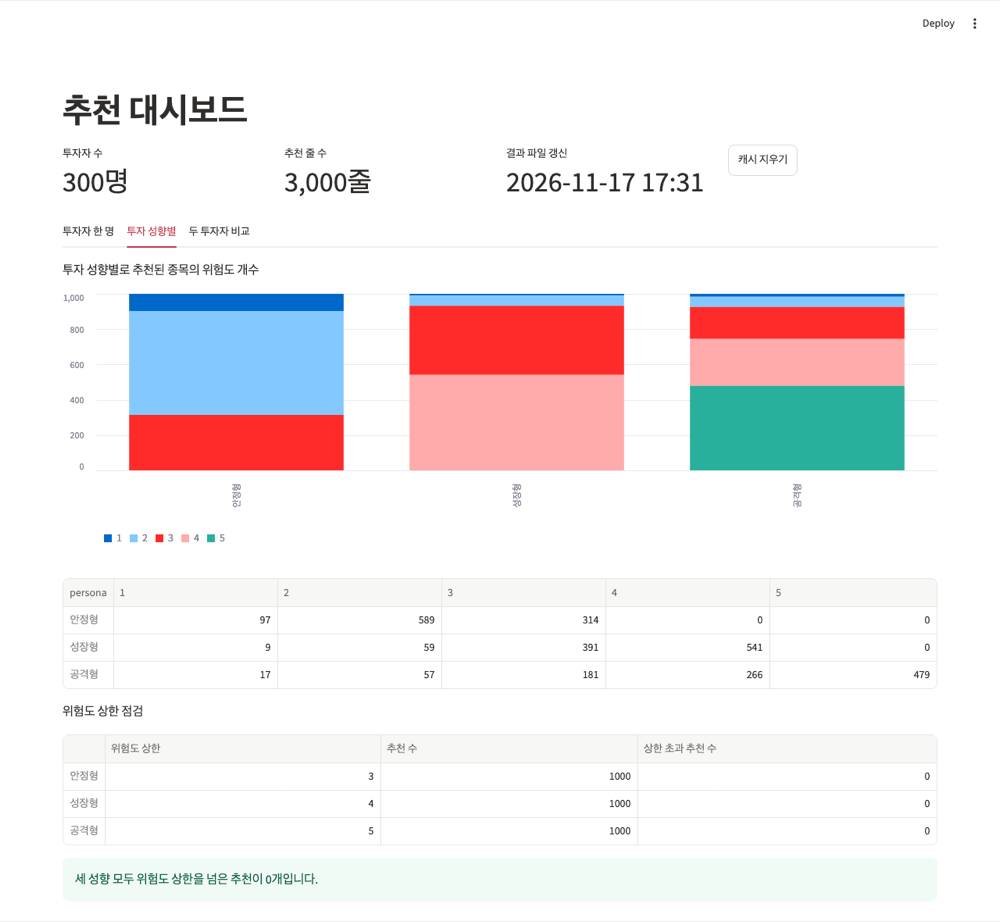

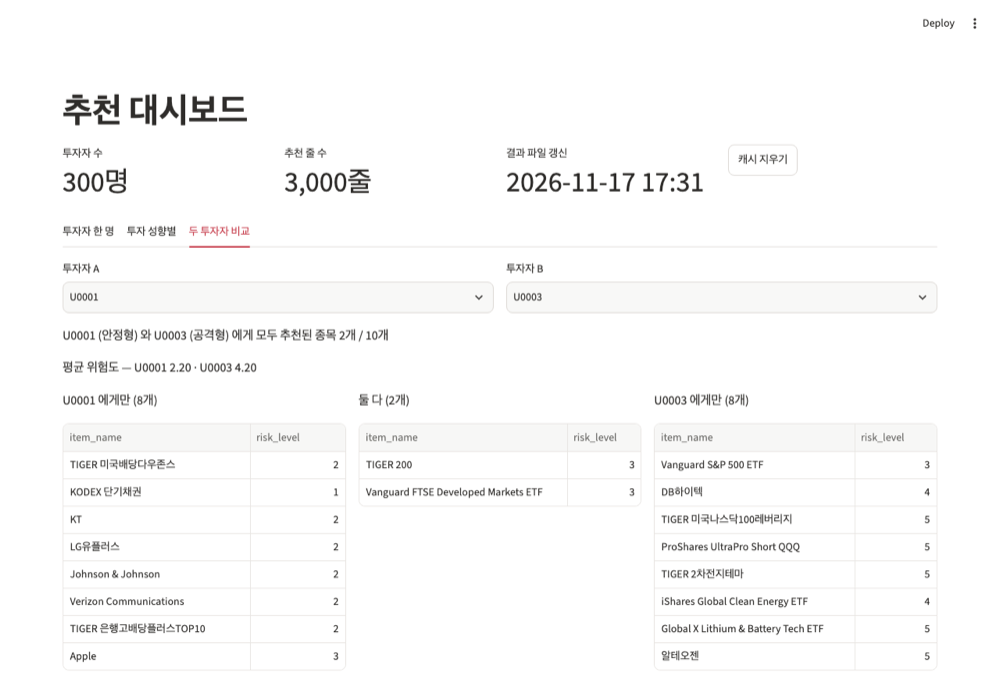

위 두 그림도 `dashboard_app.py` 를 실제로 켜서 찍은 화면입니다 (**투자 성향별** 탭과 **두 투자자 비교** 탭).

**결론: 화면에 보이는 각 부분은 앱의 `st.` 코드로 만듭니다. 코드를 읽으면 화면이 그려지는 이유를 알 수 있습니다.**

| 화면의 부분 | 앱 코드 | 노트북에서 같은 일 |
|---|---|---|
| 맨 위 「추천 대시보드」 | `st.title(...)` | — |
| 탭 세 개 | `st.tabs([...])` | 9.2 · 9.3 · 9.4 를 나눠 둔 것 |
| 투자자를 고르는 선택 상자 | `st.selectbox(...)` (Streamlit 위젯) | `투자자 = "U0001"  #@param` (Colab 입력 폼) |
| 맨 위 요약 (투자자 수 · 추천 줄 수 · 결과 파일 갱신 · 캐시 지우기 버튼) | `st.metric(...)` + `st.button(...)` | — |
| 요약 정보 세 가지 (투자 성향 · 가장 높은 위험도 · 점수 평균) | `st.columns(3)` + `.metric(...)` | `print(f"투자자 … 투자 성향 …")` |
| 「위험도 상한 3 이 지켜졌습니다」 초록 상자 | `st.success(...)` · `st.error(...)` | `print(...)` |
| 추천 10개 표 (점수는 막대) | `st.dataframe(...)` + `column_config` | `display(...)` |
| 「CSV 로 내려받기」 버튼 | `st.download_button(...)` | — |
| 성향별 막대 그림 · 교차표 · 상한 점검 표 | `st.bar_chart(분포)` + `st.dataframe(...)` | `분포.style.bar(...)` · `print(점검표...)` |
| 공통 · 한쪽에만 있는 종목 세 표 | `st.columns(3)` + `st.dataframe(...)` | `display(비교표)` |
| 「서로 다른 투자자를 고르세요」 | `st.warning(...)` | `print(...)` |

- **성향별 막대 그림** — 막대 하나가 성향 하나이고, 색은 위험도 1 \~ 5 입니다. 안정형 막대에는 위험도 4 · 5 가 없고(표에서 0), 공격형에는 위험도 5 가 479개 있습니다. 아래 「위험도 상한 점검」 표의 「상한 초과 추천 수」는 세 성향 모두 0 입니다. 막대 순서(안정형 · 성장형 · 공격형)와 숫자는 9.3 의 표와 같습니다
- **두 투자자 비교** — U0001 과 U0003 의 공통 종목 2개(`I035` · `I043`), 각자에게만 추천된 종목 8개씩, 평균 위험도 2.20 · 4.20 이 9.4 의 결과와 같습니다

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">📖 9.6 알아 둘 것 — 다시 실행 · 캐시 · 배포 · 개인정보</mark>

> 📖 **혼자 읽기** — 수업에서는 건너뛰고 복습할 때 읽는 부분입니다.

**1. Streamlit 이 동작하는 방식 — 다시 실행 (rerun)**
- 노트북은 **셀을 실행한 것만** 움직입니다. Streamlit 앱은 다릅니다. 사용자가 상자를 바꾸면 **파일 전체를 위에서 아래로 다시 실행**합니다.
- 그래서 `st.selectbox(...)` 가 돌려주는 값이 바뀌면, 그 값을 쓰는 아래 줄의 결과가 자동으로 바뀝니다.
- 단점도 있습니다. 위쪽에서 큰 파일을 읽으면 **상자를 바꿀 때마다 다시 읽게** 됩니다.

**2. 캐시 (cache)**
- `@st.cache_data` 를 함수 위에 붙이면, 같은 입력으로 다시 불렀을 때 **저장해 둔 결과를 그대로 씁니다.**
- 오늘 앱에서는 `결과_읽기` 함수에 붙어 있어서, 투자자를 바꿔도 파일을 다시 읽지 않습니다. 저장해 두는 것은 CSV 파일 자체가 아니라 함수가 돌려준 **추천표(데이터프레임)**입니다. 대신 **파일이 바뀌어도 자동으로 다시 읽지 않아** 옛 결과가 나올 수 있습니다. 새 결과가 필요하면 앱을 다시 켜거나 캐시를 지웁니다. 8주차 「API 는 켜질 때 한 번 읽는다」와 같은 문제입니다.

**3. 내 컴퓨터에서 직접 켜 보려면**
```
pip install streamlit
cd recsys/notebooks
python recommend_batch.py
streamlit run dashboard_app.py     # ← 이 줄이 앱을 켠다
```
- 설치가 끝난 뒤 위 순서로 실행하면 앱이 시작됩니다. 브라우저가 자동으로 열리지 않으면 터미널에 표시된 주소(보통 `http://localhost:8501`)를 직접 엽니다. `localhost` 는 지금 코드가 실행되는 그 컴퓨터를 가리키는 루프백 주소(`127.0.0.1`)이고, 8주차에서 본 것과 같은 뜻입니다.
- 설치와 터미널이 처음이라면 수업 후에 해 보셔도 됩니다. **수업 진행에는 필요하지 않습니다.**

**4. 배포 (deployment) — 10주차에서 조건을 점검합니다**
- 지금 앱은 **켠 컴퓨터 안**에서만 볼 수 있습니다. 다른 사람이 보게 하려면 인터넷 주소가 있어야 하고, 이것이 **배포**입니다 (8.9).
- Streamlit 앱을 배포하는 서비스(예 — Streamlit Community Cloud)가 있습니다. 가입 · 요금 조건은 바뀔 수 있어서 10주차 종합 프로젝트에서 확인합니다. 10주차에서는 배포하기 전에 필요한 것을 코드로 점검하고, 실제 배포는 하지 않습니다.

**5. 화면과 개인정보**
- 이 화면에는 투자자 번호 · **투자 성향** · 추천이 모두 나옵니다. 8.8 에서 본 것처럼 **누구에게 보일지**를 정하지 않고 인터넷에 열면 개인정보가 노출됩니다.
- 실제로는 **로그인(인증)** 으로 사용자를 확인하고, **권한**이 있는 직원에게만 보여 줍니다.

**6. 화면이 8주차 API 를 쓰게 할 수도 있습니다**
- 오늘 앱은 결과 파일을 **직접 읽습니다.** 대신 8주차 API 에 요청해서 받을 수도 있습니다. 이 경우 화면(클라이언트)과 API(서버)를 **둘 다 켜 두어야** 합니다.

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">📖 9.7 오늘의 마무리</mark>

1. 7주차 결과 파일을 읽어 **화면 세 개의 내용**을 pandas 로 만들었습니다 — 투자자 한 명 · 투자 성향별 분포 · 두 투자자 비교.
2. 투자자를 바꿔 가며 확인했고, **안정형 추천에 위험도 4 · 5 가 0개**인 것을 분포로 확인했습니다 (위험도 상한이 지켜짐).
3. 안정형 U0001 과 공격형 U0003 은 추천 10개 중 **2개만 같았고**, 평균 위험도가 2.20 과 4.20 으로 달랐습니다. 이유는 **위험도 상한**과 **개인별 취향**입니다.
4. 같은 내용이 **Streamlit 앱**(`dashboard_app.py`)에서는 선택과 출력에 `st.` 코드가 더해집니다. 앱은 위젯을 바꿀 때마다 코드를 **다시 실행**하고, 캐시로 저장해 둔 결과를 재사용합니다.

**오늘 기억할 한 줄** — **대시보드는 추천을 새로 계산하지 않고, 만들어 둔 추천을 사람이 확인하고 비교하기 쉽게 보여 줍니다.**

다음 주(10주차)에는 지금까지 만든 것을 **종합 프로젝트**로 묶고 10주를 돌아봅니다. 앱을 인터넷 주소로 여는 **배포**를 하려면 무엇이 필요한지도 점검합니다 (실제 배포는 하지 않습니다).

---

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">📝 혼자 해 보기</mark>

수업이 끝난 뒤 혼자 풀어 보는 문제입니다. 답은 바로 아래 **「답」** 에 있습니다. 먼저 스스로 생각해 본 뒤에 읽어 보세요.

**📝 혼자 해 보기 1 · 9.2 결과**

9.2 의 번호를 `U0002` 로 바꿔서 실행해 보세요. 투자 성향과 가장 높은 위험도는 무엇이고, 왜 그 위험도를 넘지 않을까요?

**📝 혼자 해 보기 2 · 9.3 결과**

9.3 의 표에서 성장형의 「위험도 5」 개수가 **0** 입니다. 이 숫자가 0 이 아니라면 어떤 문제가 있다는 뜻일까요? 그리고 이 확인을 사람이 3,000줄을 읽는 대신 표 하나로 하는 이유는 무엇일까요?

**📝 혼자 해 보기 3 · 9.5 앱**

앱에서 투자자를 바꾸면 화면이 바뀝니다. 파일이 아주 커서 앱이 느려진다면 가장 먼저 어디를 의심하고, 무엇으로 줄일 수 있을까요?

- 힌트 — 9.6 의 「다시 실행」과 「캐시」를 읽어 보세요.

**📝 혼자 해 보기 4 · 9.6 개인정보**

이 앱을 인증 없이 회사 밖 인터넷에 그대로 열면 어떤 문제가 생길까요?

- 힌트 — 앱 화면에 투자 성향이 나옵니다. 8.8 에서 번호를 차례로 바꿔 요청했던 일을 떠올려 보세요.

### <mark style="display:block; background:#f8bbd0; color:#1a1a1a; padding:6px 12px; border-radius:4px">답</mark>

먼저 스스로 답을 생각해 본 뒤에 읽어 보세요. 답에 나오는 숫자는 모두 이 노트북을 실제로 실행해서 얻은 값입니다.

**함께 보기 답 — 두 사람의 추천이 다른 이유를 위험도 상한과 개인별 취향으로 나눠 설명해 주어야 합니다**

- **위험도 상한** — 안정형은 위험도 3 까지, 공격형은 5 까지만 추천받습니다 (6주차 적합성원칙). 그래서 안정형의 추천에는 위험도 4 · 5 가 처음부터 들어올 수 없습니다 (9.3 의 0 개)
- **개인별 취향** — 같은 성향이어도 투자자마다 담은 종목이 달라서, 행렬분해가 계산한 추천 점수가 다릅니다
- 상담 직원은 「성향에 맞는 위험도 범위 안에서, 고객님과 비슷한 기록을 가진 투자자들이 많이 담은 종목을 골랐습니다」라고 설명할 수 있습니다
- 화면에서 **같은 성향 두 사람**도 비교해 보면, 성향이 같아도 추천이 다를 수 있다는 것을 설명하기 쉽습니다
- **한 줄로 정리하면** — 화면의 숫자는 이유와 함께 설명해야 설명 자료가 됩니다.

**혼자 해 보기 1 답 — 성장형이고 가장 높은 위험도는 4 입니다. 성장형의 위험도 상한이 4 이기 때문입니다**

- U0002 는 성장형이고, 추천 10개의 가장 높은 위험도는 **4**, 점수 평균은 **0.5161** 입니다
- 추천을 만들 때 `추천하기` 함수가 위험도 상한을 넘는 종목을 **거르기** 때문입니다 (7.3 의 3단계)
- 7주차 규격 검사도 저장하기 전에 상한 초과가 없는지 한 번 더 확인합니다
- **한 줄로 정리하면** — 화면의 숫자가 상한을 넘지 않는 것은 화면이 아니라, 추천을 만드는 단계에서 이미 걸러졌기 때문입니다.

**혼자 해 보기 2 답 — 0 이 아니라면 상한을 넘는 추천이 고객에게 나갔다는 뜻이라서 심각한 문제입니다. 표 하나로 하면 빠르고 빠뜨리지 않기 때문입니다**

- 성장형에게 위험도 5 종목이 추천된 것이므로, 6주차의 적합성원칙(투자 성향보다 위험한 상품을 권하지 않는다)을 어긴 것입니다
- 3,000줄을 눈으로 읽으면 시간이 오래 걸리고 한 줄을 놓칠 수 있습니다. 성향 × 위험도 교차표는 **한눈에** 보이고, 0 이 곧 확인 결과입니다
- 이런 요약 표를 정기적으로 보면, 추천 방식을 바꿨을 때 상한이 깨졌는지 바로 알 수 있습니다
- **한 줄로 정리하면** — 분포 표는 큰 표에서 「이상한 곳」을 빠르게 찾는 확인 도구입니다.

**혼자 해 보기 3 답 — 파일을 다시 읽는 곳을 의심하고, 캐시로 한 번만 읽게 줄입니다**

- Streamlit 앱은 투자자를 바꿀 때마다 **파일 전체를 다시 실행**합니다. 위쪽에서 큰 파일을 읽으면 그때마다 다시 읽어 느려집니다
- `@st.cache_data` 를 파일을 읽는 함수에 붙이면 같은 호출에서는 **저장해 둔 결과를 재사용**합니다
- 파일이 바뀐 뒤에는 앱을 다시 켜거나 캐시를 지워야 새 내용이 반영됩니다 (8주차 혼자 해 보기 2 와 같은 문제)
- **한 줄로 정리하면** — 다시 실행되는 구조에서는 무거운 일을 캐시로 한 번만 하게 합니다.

**혼자 해 보기 4 답 — 번호만 바꿔 가며 300명의 투자 성향과 추천이 모두 보입니다. 인증 · 권한으로 막아야 합니다**

- 화면에서 투자자를 고르는 선택 상자에 `U0001` \~ `U0300` 이 모두 들어 있어서, **누구나** 한 명씩 확인할 수 있습니다 (8.8 에서 요청 300번으로 확인한 것과 같습니다)
- 투자 성향은 금융 **개인정보**입니다
- 그래서 화면도 **로그인(인증)** 으로 사용자를 확인하고, **권한**이 있는 직원에게만 보이게 하고, 접속 기록을 남깁니다
- **한 줄로 정리하면** — API 든 화면이든 인터넷에 여는 순간 「누가 볼 수 있는가」가 먼저 정해져야 합니다.